# 보충 분석: 주성분 분석(PCA)으로 본 사업장 데이터 (13주차)

메인 노트북(`nps_exit_prediction.ipynb`)과 같은 데이터(기준월 2026-07, 513,541곳, 17개 변수)에
13주차에서 배운 PCA를 적용해 본다.

1. 17개 변수를 주성분으로 나누면 몇 개면 충분한가? (설명된 분산)
2. 2차원으로 줄여서 보면 탈퇴 사업장이 따로 모여 있는가? (시각화)
3. PCA로 줄인 데이터로 학습하면 성능·속도가 어떻게 바뀌는가? (분류기와 함께 사용하기)
4. PCA 공간에서 K-means로 사업장 유형을 나누면 유형별 탈퇴율은? (군집과 함께 사용하기)

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys, os, time

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid', {'font.family': 'Malgun Gothic'})
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

sys.path.append('src')
from dataset import build_dataset, FEATURES

t = time.time()
X, y, d = build_dataset('202607', '202606', '202604', '202603', '202610')
print(f'{len(X):,}곳, 탈퇴 {y.sum():,}곳 ({y.mean()*100:.3f}%)  ({time.time()-t:.0f}s)')

513,541곳, 탈퇴 2,033곳 (0.396%)  (49s)


## 1. 표준화 후 PCA — 설명된 분산 (13주차 `explained_variance_ratio_`)
PCA는 분산이 큰 방향을 찾으므로, 단위가 다른 변수(원, 명, 년)를 그대로 쓰면 큰 숫자의 변수가 주성분을 독차지한다.
그래서 먼저 `StandardScaler`로 표준화한다(4·5주차).

주성분별 설명된 분산 비율: [0.173 0.147 0.089 0.077 0.068 0.06  0.057 0.055 0.049 0.046 0.04  0.039
 0.036 0.031 0.021 0.008 0.002]
누적 90%에 필요한 주성분 수: 12개 (원래 변수 17개)


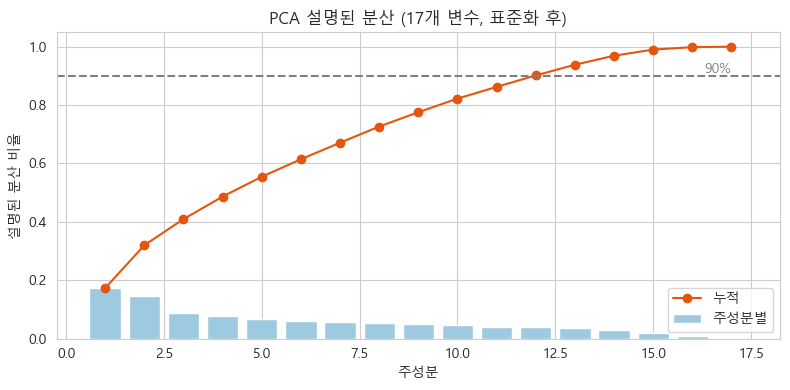

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_sc = StandardScaler().fit_transform(X)
pca_full = PCA()
pca_full.fit(X_sc)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n90 = int(np.argmax(cum >= 0.9) + 1)
print('주성분별 설명된 분산 비율:', np.round(evr, 3))
print(f'누적 90%에 필요한 주성분 수: {n90}개 (원래 변수 {X.shape[1]}개)')

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(evr) + 1), evr, color='#9ecae1', label='주성분별')
ax.plot(range(1, len(evr) + 1), cum, marker='o', color='#e6550d', label='누적')
ax.axhline(0.9, color='gray', linestyle='--'); ax.text(len(evr), 0.91, '90%', ha='right', color='gray')
ax.set_xlabel('주성분'); ax.set_ylabel('설명된 분산 비율'); ax.set_title('PCA 설명된 분산 (17개 변수, 표준화 후)')
ax.legend()
save('13_pca_variance')
plt.show()

과일 사진(10,000픽셀)은 50개 주성분으로 92%를 설명했지만, 이 데이터는 17개 변수가 서로 상관이 낮아
(5-6장 히트맵) 분산이 여러 주성분에 고르게 퍼져 있다. 즉 **줄일 여지가 크지 않은 데이터**다.

## 2. 주성분이 무엇을 뜻하는가 — 로딩(loading)

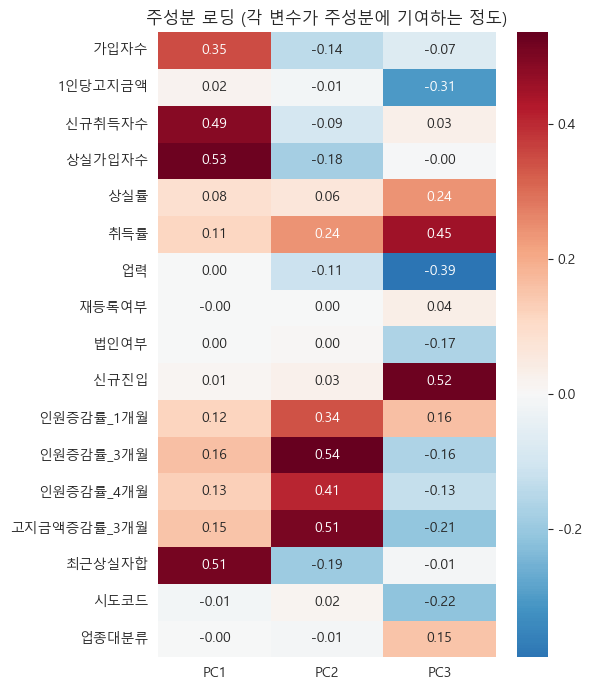

PC1 주요 변수: ['상실가입자수', '최근상실자합', '신규취득자수']
PC2 주요 변수: ['인원증감률_3개월', '고지금액증감률_3개월', '인원증감률_4개월']
PC3 주요 변수: ['신규진입', '취득률', '업력']


In [3]:
load = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=['PC1', 'PC2', 'PC3'])
plt.figure(figsize=(6, 7))
sns.heatmap(load, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('주성분 로딩 (각 변수가 주성분에 기여하는 정도)')
save('14_pca_loadings')
plt.show()
for pc in ['PC1', 'PC2', 'PC3']:
    top = load[pc].abs().sort_values(ascending=False).index[:3]
    print(pc, '주요 변수:', list(top))

## 3. 2차원으로 줄여서 보기 (13주차 시각화)

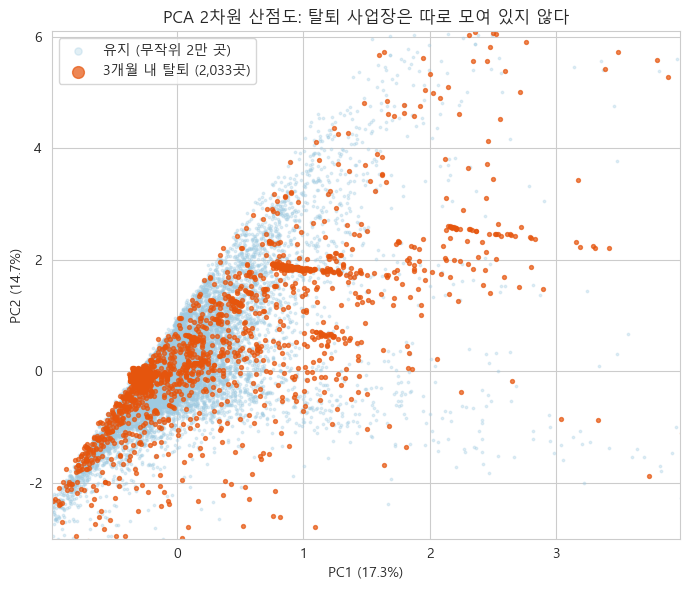

2개 주성분이 설명하는 분산: 32.0%


In [4]:
pca2 = PCA(n_components=2)
Z = pca2.fit_transform(X_sc)
rng = np.random.RandomState(42)
idx0 = rng.choice(np.where(y.values == 0)[0], 20000, replace=False)
idx1 = np.where(y.values == 1)[0]

plt.figure(figsize=(7, 6))
plt.scatter(Z[idx0, 0], Z[idx0, 1], s=3, alpha=0.3, color='#9ecae1', label='유지 (무작위 2만 곳)')
plt.scatter(Z[idx1, 0], Z[idx1, 1], s=8, alpha=0.7, color='#e6550d', label='3개월 내 탈퇴 (2,033곳)')
plt.xlim(np.percentile(Z[:, 0], [0.5, 99.5])); plt.ylim(np.percentile(Z[:, 1], [0.5, 99.5]))
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)'); plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)')
plt.title('PCA 2차원 산점도: 탈퇴 사업장은 따로 모여 있지 않다')
plt.legend(markerscale=3)
save('15_pca_scatter')
plt.show()
print(f'2개 주성분이 설명하는 분산: {pca2.explained_variance_ratio_.sum()*100:.1f}%')

과일 사진은 2차원만으로도 사과·바나나·파인애플이 뚜렷하게 갈라졌지만, 이 데이터에서는 탈퇴 사업장이
유지 사업장 사이에 섞여 있다. 하나의 직선이나 두 개의 축으로는 구분되지 않는 **어려운 문제**라는 뜻이고,
여러 변수의 조합을 나무 구조로 학습하는 트리 앙상블이 필요한 이유이기도 하다.

## 4. 분류기와 함께 사용하기: 원본 vs PCA (13주차)
교안처럼 원본 데이터와 PCA로 줄인 데이터로 같은 모델을 학습해 성능과 학습 시간을 비교한다.
메인 노트북 7장과 같은 15만 행 층화 표본, 층화 5-겹 교차검증을 쓴다.
PCA는 교차검증의 각 학습 fold 안에서만 fit 하도록 `make_pipeline`으로 묶는다(정보 누수 방지).

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_cv, _, y_cv, _ = train_test_split(X_train, y_train, train_size=150000, stratify=y_train, random_state=42)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rf = lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=42)

setups = {
    f'원본 17개 변수': make_pipeline(StandardScaler(), rf()),
    f'PCA 90% ({n90}개 주성분)': make_pipeline(StandardScaler(), PCA(n_components=0.9), rf()),
    'PCA 2개 주성분': make_pipeline(StandardScaler(), PCA(n_components=2), rf()),
}
rows = []
for name, model in setups.items():
    s = cross_validate(model, X_cv, y_cv, cv=skf, scoring=['average_precision', 'roc_auc', 'recall'])
    rows.append({'입력': name, 'PR-AUC': s['test_average_precision'].mean(), 'PR-AUC std': s['test_average_precision'].std(),
                 'ROC-AUC': s['test_roc_auc'].mean(), '학습 시간(s)': s['fit_time'].mean()})
    print(name, 'done')
pca_cmp = pd.DataFrame(rows).set_index('입력')
pca_cmp.to_csv('results/pca_vs_original.csv', encoding='utf-8-sig')
pca_cmp.round(4)

원본 17개 변수 done


PCA 90% (12개 주성분) done


PCA 2개 주성분 done


,PR-AUC,PR-AUC std,ROC-AUC,학습 시간(s)
입력,,,,
원본 17개 변수,0.1830,0.0177,0.8455,8.6463
PCA 90% (12개 주성분),0.1466,0.0228,0.8189,21.6324
PCA 2개 주성분,0.0576,0.0108,0.6680,7.2734


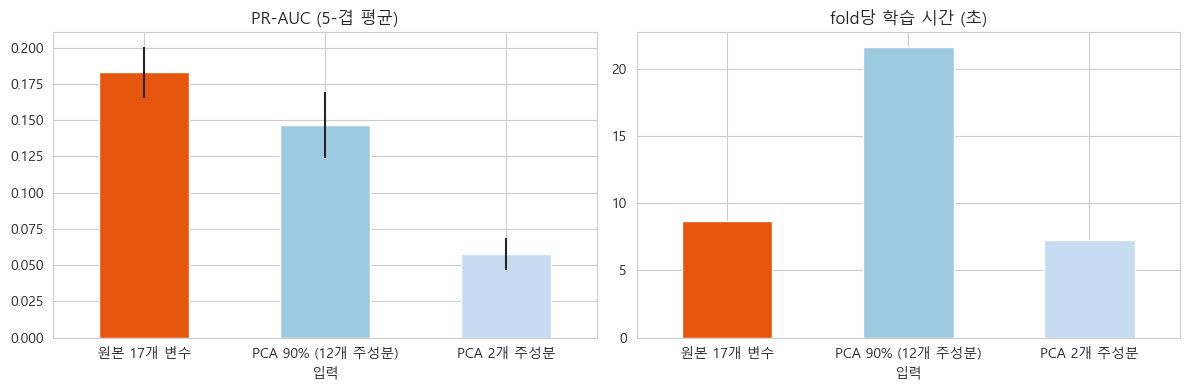

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
pca_cmp['PR-AUC'].plot(kind='bar', ax=ax[0], color=['#e6550d', '#9ecae1', '#c6dbef'], yerr=pca_cmp['PR-AUC std'])
ax[0].set_title('PR-AUC (5-겹 평균)'); ax[0].tick_params(axis='x', rotation=0)
pca_cmp['학습 시간(s)'].plot(kind='bar', ax=ax[1], color=['#e6550d', '#9ecae1', '#c6dbef'])
ax[1].set_title('fold당 학습 시간 (초)'); ax[1].tick_params(axis='x', rotation=0)
save('16_pca_vs_original')
plt.show()

## 5. 군집과 함께 사용하기: PCA 공간에서 K-means (6·13주차)
PCA로 줄인 공간에서 사업장을 K-means로 묶고, 군집별 탈퇴율과 특징을 비교한다.
엘보·실루엣 대신 해석이 쉬운 4개 군집으로 고정한다.

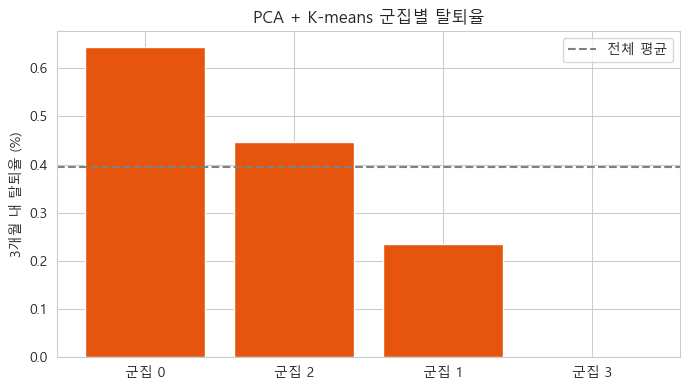

,사업장수,탈퇴율,가입자수_중앙,업력_중앙,신규진입_비율,건설업_비율,상실률_평균
군집,,,,,,,
0,180964,0.644,6.0,8.569,0.350,0.147,0.038
2,40112,0.446,14.0,8.249,0.135,0.006,0.035
1,292437,0.235,7.0,10.913,0.005,0.152,0.024
3,28,0.000,8128.5,20.966,0.107,0.000,0.131


In [7]:
from sklearn.cluster import KMeans
pca_k = PCA(n_components=n90)
Zk = pca_k.fit_transform(X_sc)
km = KMeans(n_clusters=4, random_state=42, n_init=10)
d['군집'] = km.fit_predict(Zk)

prof = d.groupby('군집').agg(사업장수=('탈퇴', 'size'), 탈퇴율=('탈퇴', 'mean'),
                            가입자수_중앙=('가입자수', 'median'), 업력_중앙=('업력', 'median'),
                            신규진입_비율=('신규진입', 'mean'), 건설업_비율=('건설업', 'mean'),
                            상실률_평균=('상실률', 'mean'))
prof['탈퇴율'] = prof['탈퇴율'] * 100
prof = prof.sort_values('탈퇴율', ascending=False)
prof.to_csv('results/pca_kmeans_profile.csv', encoding='utf-8-sig')

plt.figure(figsize=(7, 4))
plt.bar([f'군집 {c}' for c in prof.index], prof['탈퇴율'], color='#e6550d')
plt.axhline(y.mean() * 100, color='gray', linestyle='--', label='전체 평균')
plt.ylabel('3개월 내 탈퇴율 (%)'); plt.title('PCA + K-means 군집별 탈퇴율'); plt.legend()
save('17_pca_kmeans')
plt.show()
prof.round(3)

## 6. 정리

In [8]:
print(f'- 17개 변수 → 누적 90%에 {n90}개 주성분 필요 (줄일 여지가 작음)')
print(f'- PCA 2차원 산점도에서 탈퇴 사업장은 따로 모이지 않음')
for name, r in pca_cmp.iterrows():
    print(f'- {name}: PR-AUC {r["PR-AUC"]:.3f}, fold당 학습 {r["학습 시간(s)"]:.1f}s')
top = prof.iloc[0]
print(f'- 탈퇴율이 가장 높은 군집: 탈퇴율 {top["탈퇴율"]:.2f}%, 신규진입 {top["신규진입_비율"]*100:.0f}%, 건설업 {top["건설업_비율"]*100:.0f}%')

- 17개 변수 → 누적 90%에 12개 주성분 필요 (줄일 여지가 작음)
- PCA 2차원 산점도에서 탈퇴 사업장은 따로 모이지 않음
- 원본 17개 변수: PR-AUC 0.183, fold당 학습 8.6s
- PCA 90% (12개 주성분): PR-AUC 0.147, fold당 학습 21.6s
- PCA 2개 주성분: PR-AUC 0.058, fold당 학습 7.3s
- 탈퇴율이 가장 높은 군집: 탈퇴율 0.64%, 신규진입 35%, 건설업 15%
